<a href="https://colab.research.google.com/github/ayatahiri2005-hash/tp3-vision-par-ordinateur/blob/main/part_one.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**EXERCICE 2**

In [ ]:
import cv2

cap = cv2.VideoCapture(0)  # 0 = webcam (essaie 1 si ça ne marche pas)

while True:
    ret, frame = cap.read()
    if not ret:
        break

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    cv2.imshow('Webcam originale', frame)
    cv2.imshow('Webcam en niveaux de gris', gray)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

In [ ]:
import cv2

cap = cv2.VideoCapture(0)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter('sortie_gris.mp4', fourcc, 20.0, (w, h), isColor=False)

while True:
    ret, frame = cap.read()
    if not ret:
        break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    out.write(gray)
    cv2.imshow('Enregistrement', gray)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
out.release()
cv2.destroyAllWindows()

In [ ]:
import cv2

cap = cv2.VideoCapture("C:\Users\A\Downloads\sample-10s.mp4")   # chemin de la vidéo
fps = cap.get(cv2.CAP_PROP_FPS) or 25
delai = int(1000 / fps)                  # pour lire à vitesse normale

while True:
    ret, frame = cap.read()
    if not ret:                          # fin de la vidéo
        print("Fin de la vidéo")
        break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    cv2.imshow('Video en gris', gray)
    if cv2.waitKey(delai) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

### Question : que se passe-t-il si on utilise une vidéo enregistrée à la place de la webcam ?

Il suffit de remplacer `cv2.VideoCapture(0)` par `cv2.VideoCapture("chemin/video.mp4")`. Le reste du code ne change pas.
Différences :
- La vidéo a une **fin** : à la dernière image, `cap.read()` renvoie `ret = False` et la boucle s'arrête automatiquement (une webcam, elle, tourne indéfiniment).
- La vitesse de lecture dépend de `waitKey(...)` : avec `waitKey(1)` la vidéo est lue le plus vite possible (accélérée). Pour une vitesse normale, on utilise `1000/fps` ms (`cap.get(cv2.CAP_PROP_FPS)`).
- On peut connaître à l'avance le nombre d'images (`CAP_PROP_FRAME_COUNT`) et se déplacer dans la vidéo, ce qui est impossible avec une webcam.
- Si le chemin est faux, `cap.isOpened()` vaut `False` et `ret` est `False` dès la première lecture.

Resultat avec capture d'ecran
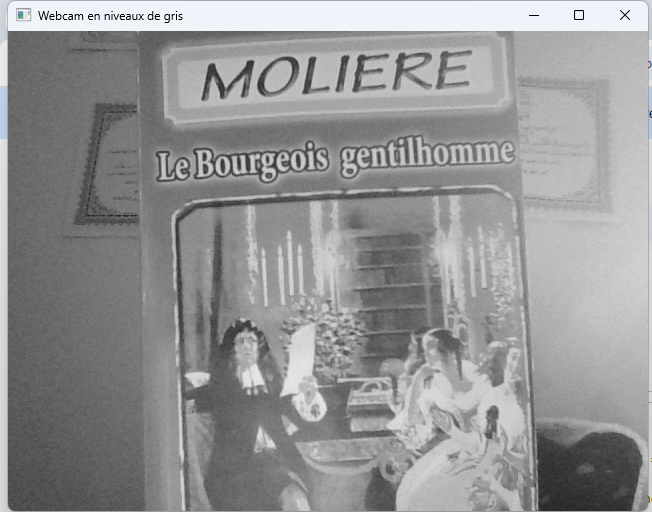
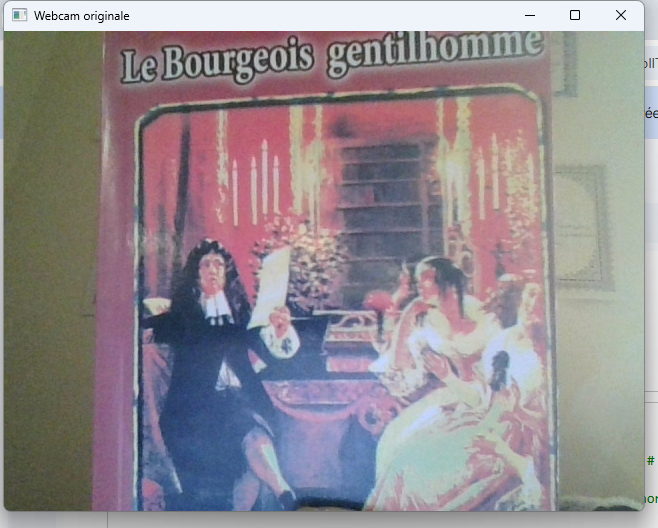

**EXERCICE 4**

In [ ]:
!apt-get install -y cmake libopenblas-dev liblapack-dev
!pip install dlib face_recognition

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
cmake is already the newest version (3.28.3-1build7).
libopenblas-dev is already the newest version (0.3.26+ds-1ubuntu0.1).
liblapack-dev is already the newest version (3.12.0-3build1.1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 MB 67.7 MB/s  0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for face-recognition-models: filename=face_recognition_models-0.3.0-py2.py3-none-any.whl size=100566240 sha256=7e1850ca0aec95d1520dc60e9e7a59510be8f4675fd4011c16f729da3ba2c56d
  Stored in directory: /root/.cache/pip/wheels/39/20/47/6b647a3457f0e36c161b2516a5bd7f29f6bbd5e3a67c46a710
Successfully built face-recognition-models
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [face_recognition]


In [ ]:
from google.colab import files
uploaded = files.upload()   # puis j'ai choisis people.jpg

Saving people.jpg to people (1).jpg


Nombre de visages détectés : 10


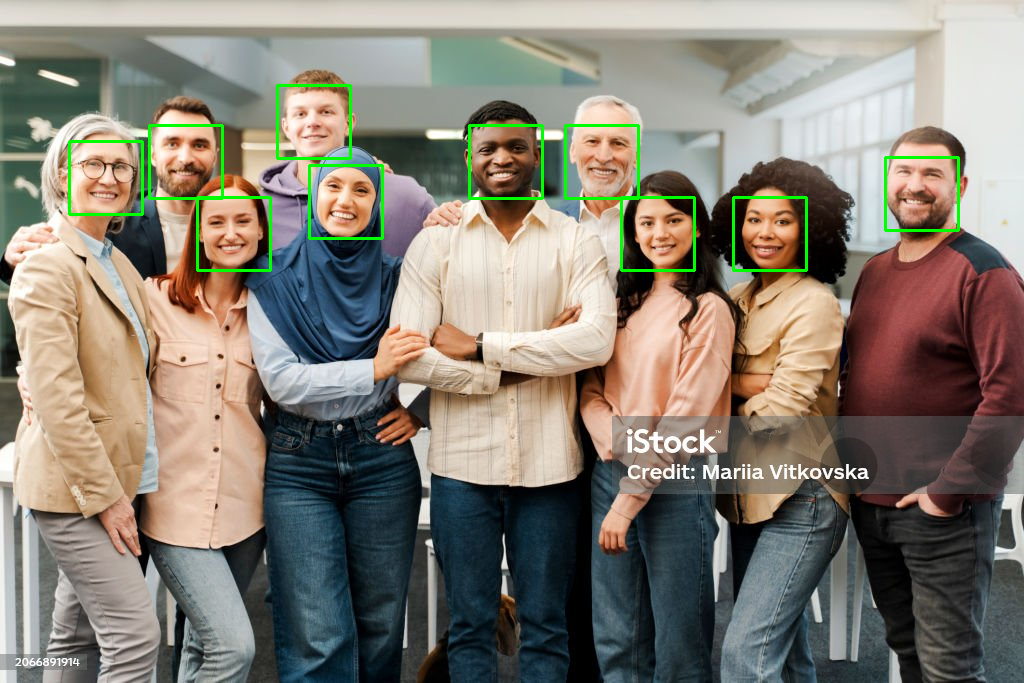

In [ ]:
import dlib
import cv2
from google.colab.patches import cv2_imshow

detector = dlib.get_frontal_face_detector()
img = cv2.imread('people (1).jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

faces = detector(gray)
print("Nombre de visages détectés :", len(faces))

for face in faces:
    x, y, w, h = face.left(), face.top(), face.width(), face.height()
    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)

cv2_imshow(img)

**resultat avec capture d'écran**
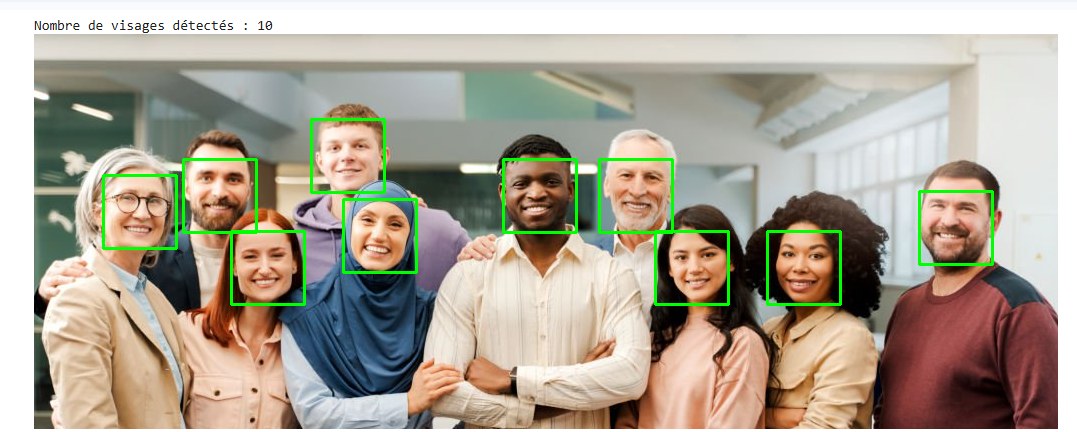

**EXERCICE 5**

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving test.jpg to test.jpg


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving ref.jpg to ref.jpg


In [ ]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"   # désactiver CUDA pour dlib
import face_recognition

image_ref = face_recognition.load_image_file("ref.jpg")
image_test = face_recognition.load_image_file("test.jpg")

encodages_ref = face_recognition.face_encodings(image_ref)
encodages_test = face_recognition.face_encodings(image_test)

if len(encodages_ref) == 0 or len(encodages_test) == 0:
    print("Aucun visage détecté dans l'une des images.")
else:
    encodage_ref = encodages_ref[0]
    encodage_test = encodages_test[0]

    result = face_recognition.compare_faces([encodage_ref], encodage_test)
    distance = face_recognition.face_distance([encodage_ref], encodage_test)[0]

    print("Même personne ?", result[0])
    print("Distance :", round(distance, 3), "(seuil par défaut = 0.6)")

/usr/local/lib/python3.13/dist-packages/face_recognition_models/__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


Même personne ? False
Distance : 0.856 (seuil par défaut = 0.6)


In [ ]:
print("Visages dans l'image test :", len(encodages_test))

for i, enc in enumerate(encodages_test):
    match = face_recognition.compare_faces([encodage_ref], enc)[0]
    dist = face_recognition.face_distance([encodage_ref], enc)[0]
    print(f"Visage {i+1} -> même personne : {match} (distance = {dist:.3f})")

Visages dans l'image test : 1
Visage 1 -> même personne : False (distance = 0.856)


### Question 1 : que se passe-t-il si l'image test contient plusieurs visages ?

`face_recognition.face_encodings(image)` renvoie une **liste** avec un encodage (vecteur de 128 valeurs) par visage détecté. Avec `[0]`, on ne compare que le **premier visage trouvé**, qui n'est pas forcément la personne recherchée : le résultat peut donc être faux. Si aucun visage n'est détecté, la liste est vide et `[0]` provoque une erreur `IndexError`.
Solution : parcourir tous les encodages avec une boucle, comparer chacun à la référence (`compare_faces` / `face_distance`) et retenir celui dont la distance est la plus petite.

### Question 2 : quelle précision attendre dans des conditions réelles ?

Le modèle de dlib annonce environ **99,38 %** de précision sur le benchmark LFW, mais ce sont des conditions favorables (visages de face, bien éclairés). En conditions réelles, la précision est plus faible car elle est affectée par :
- l'éclairage (ombres, contre-jour, faible luminosité),
- l'angle du visage (profil, tête penchée),
- les occlusions (lunettes de soleil, masque, casquette, main),
- la résolution et le flou, ainsi que le vieillissement ou le changement d'apparence (barbe, coiffure),
- la distance à la caméra (visage trop petit).
On peut s'attendre à des erreurs : faux positifs (deux personnes différentes jugées identiques) et faux négatifs. Le seuil `tolerance` (0.6 par défaut) règle le compromis : plus il est bas (ex. 0.5), plus le système est strict. De plus, le détecteur de dlib (HOG) est surtout fiable pour des visages frontaux. Pour des applications sensibles, il faut plusieurs images de référence par personne et un seuil adapté.

**Exercice 6**

Visages : 10


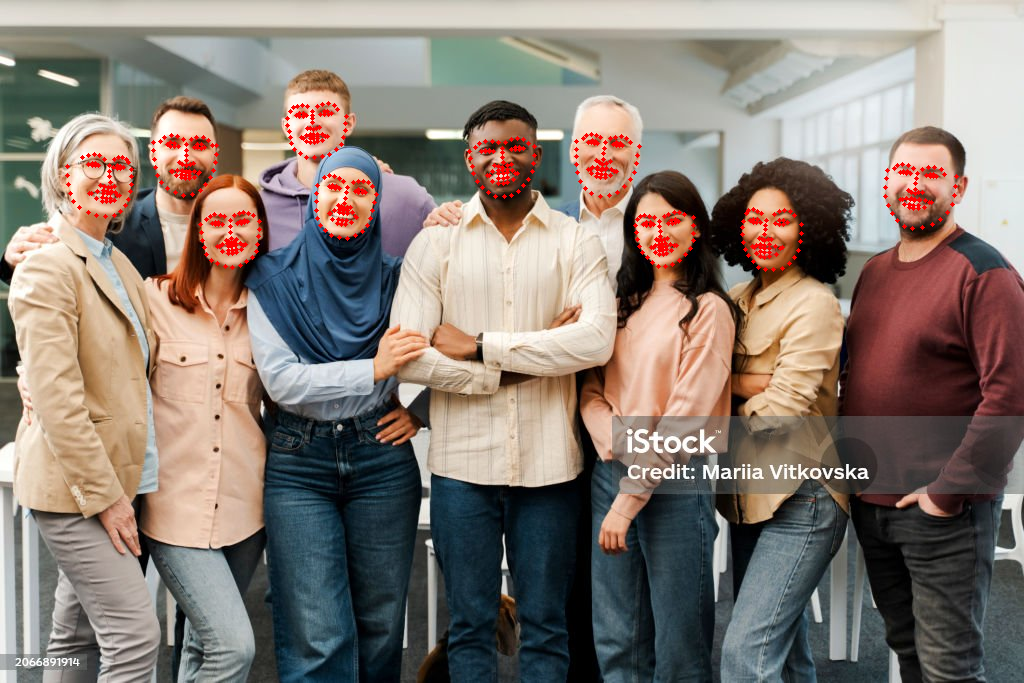

In [ ]:
import cv2
import face_recognition
from google.colab.patches import cv2_imshow

img = cv2.imread('people (1).jpg')
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # face_recognition attend du RGB

landmarks_list = face_recognition.face_landmarks(rgb)
print("Visages :", len(landmarks_list))

for landmarks in landmarks_list:
    for partie, points in landmarks.items():
        for (x, y) in points:
            cv2.circle(img, (x, y), 2, (0, 0, 255), -1)

cv2_imshow(img)

In [ ]:
print("Parties retournées :")
for partie, points in landmarks_list[0].items():
    print(f"- {partie} : {len(points)} points")

Parties retournées :
- chin : 17 points
- left_eyebrow : 5 points
- right_eyebrow : 5 points
- nose_bridge : 4 points
- nose_tip : 5 points
- left_eye : 6 points
- right_eye : 6 points
- top_lip : 12 points
- bottom_lip : 12 points


In [ ]:
import numpy as np

def eye_aspect_ratio(eye):
    # eye = liste de 6 points (x, y)
    eye = np.array(eye)
    A = np.linalg.norm(eye[1] - eye[5])   # distance verticale 1
    B = np.linalg.norm(eye[2] - eye[4])   # distance verticale 2
    C = np.linalg.norm(eye[0] - eye[3])   # distance horizontale
    return (A + B) / (2.0 * C)

for i, landmarks in enumerate(landmarks_list):
    ear_gauche = eye_aspect_ratio(landmarks["left_eye"])
    ear_droit = eye_aspect_ratio(landmarks["right_eye"])
    ear = (ear_gauche + ear_droit) / 2.0
    etat = "yeux fermés" if ear < 0.2 else "yeux ouverts"
    print(f"Visage {i+1} : EAR = {ear:.3f} -> {etat}")

Visage 1 : EAR = 0.203 -> yeux ouverts
Visage 2 : EAR = 0.317 -> yeux ouverts
Visage 3 : EAR = 0.234 -> yeux ouverts
Visage 4 : EAR = 0.225 -> yeux ouverts
Visage 5 : EAR = 0.332 -> yeux ouverts
Visage 6 : EAR = 0.289 -> yeux ouverts
Visage 7 : EAR = 0.301 -> yeux ouverts
Visage 8 : EAR = 0.268 -> yeux ouverts
Visage 9 : EAR = 0.180 -> yeux fermés
Visage 10 : EAR = 0.125 -> yeux fermés


In [ ]:
EAR_SEUIL = 0.2        # en dessous = œil fermé
DUREE_ALERTE = 2.0     # secondes
FPS = 20               # images par seconde de la vidéo
NB_IMAGES_ALERTE = int(DUREE_ALERTE * FPS)

compteur = 0
# Dans la boucle vidéo, pour chaque image :
#   if ear < EAR_SEUIL:
#       compteur += 1
#       if compteur >= NB_IMAGES_ALERTE:
#           print("ALERTE SOMNOLENCE !")
#   else:
#       compteur = 0

### Question 1 : parties du visage retournées par `face_landmarks`

Un dictionnaire contenant 9 parties (68 points au total en dlib) :
- `chin` : contour du menton / mâchoire
- `left_eyebrow` et `right_eyebrow` : sourcils
- `nose_bridge` : arête du nez
- `nose_tip` : bas du nez / narines
- `left_eye` et `right_eye` : yeux (6 points chacun)
- `top_lip` et `bottom_lip` : lèvre supérieure et inférieure

### Question 2 : EAR (Eye Aspect Ratio)

EAR = (‖p2 − p6‖ + ‖p3 − p5‖) / (2 × ‖p1 − p4‖)
où p1 et p4 sont les coins de l'œil (distance horizontale) et p2, p3, p5, p6 les points des paupières (distances verticales).

- Œil ouvert : EAR autour de 0,25 à 0,35, à peu près constant.
- Œil fermé : les distances verticales tendent vers 0, donc EAR chute (< 0,2 environ).
**Clignement** : l'EAR descend brièvement sous le seuil
puis remonte.
**Somnolence** : l'EAR reste sous le seuil pendant une durée anormalement longue (par ex. plus de 2 secondes, soit N images consécutives), ou le nombre de clignements lents augmente. Dans ce cas, on déclenche une alerte sonore. Le rapport est invariant à l'échelle (il ne dépend pas de la distance à la caméra), et on peut moyenner les deux yeux pour plus de robustesse. Le seuil doit être ajusté selon la personne.



resultat avec capture d'écran 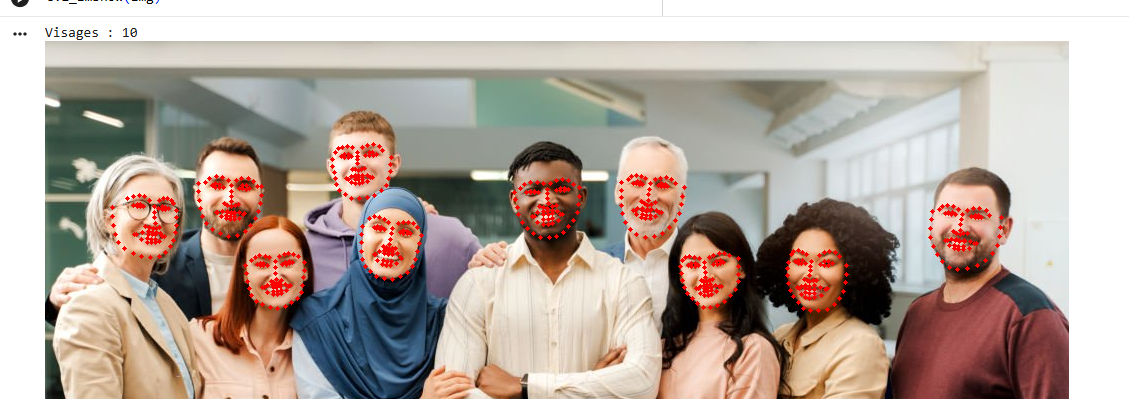

***MINI PROJET***

Visages détectés : 10


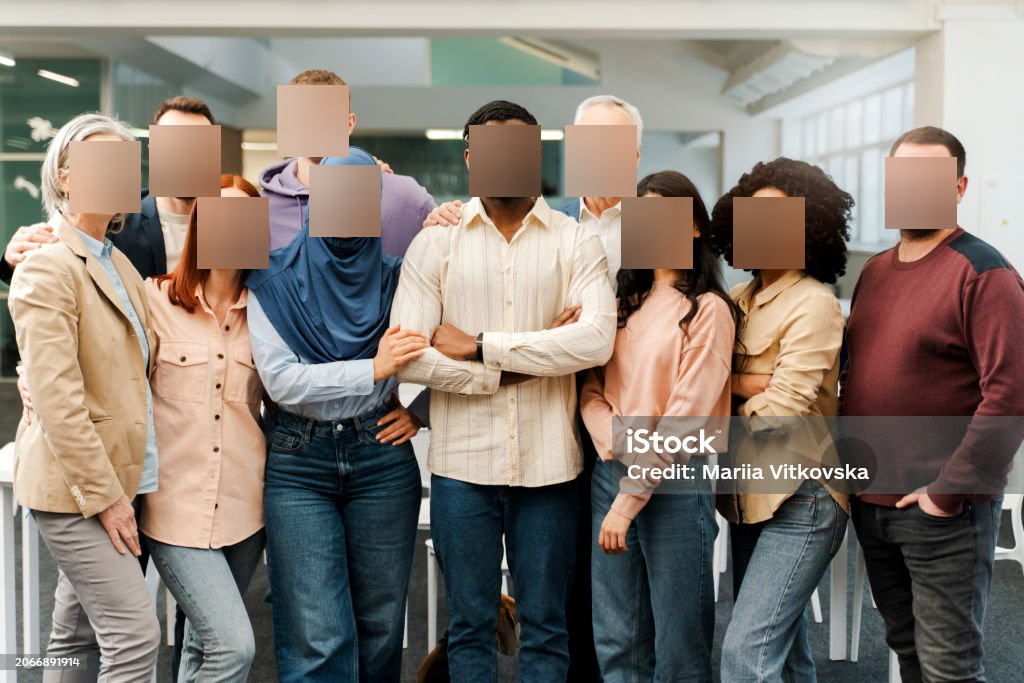

True

In [ ]:
import cv2
import dlib

try:
    from google.colab.patches import cv2_imshow
except ImportError:
    import matplotlib.pyplot as plt
    def cv2_imshow(img):
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.axis('off')
        plt.show()

nom_image = "people (1).jpg"
img = cv2.imread(nom_image)
if img is None:
    raise FileNotFoundError(f"Image '{nom_image}' introuvable")

detector = dlib.get_frontal_face_detector()
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
faces = detector(gray)
print("Visages détectés :", len(faces))

for face in faces:
    x1 = max(face.left(), 0)
    y1 = max(face.top(), 0)
    x2 = min(face.right(), img.shape[1])
    y2 = min(face.bottom(), img.shape[0])

    zone = img[y1:y2, x1:x2]
    if zone.size == 0:
        continue
    # (99, 99) = taille du noyau, doit être impair ; plus grand = plus flou
    img[y1:y2, x1:x2] = cv2.GaussianBlur(zone, (99, 99), 30)

cv2_imshow(img)
cv2.imwrite("people_floute.jpg", img)

Resultat avec capture d'écran 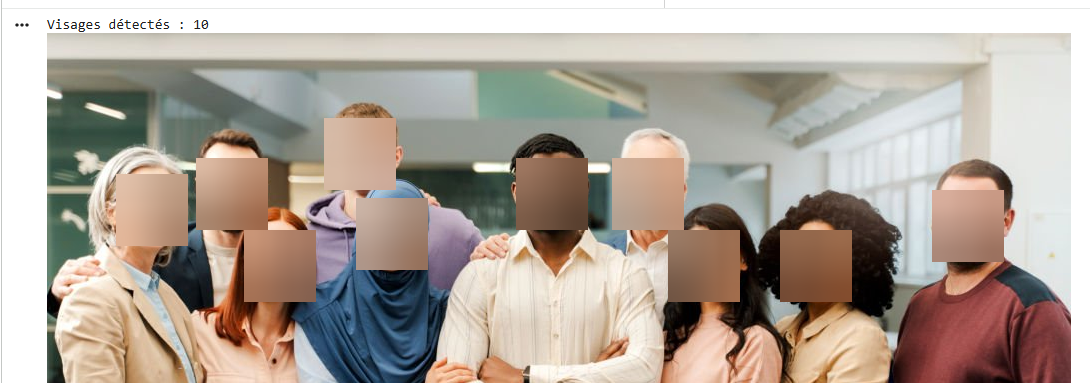